In [7]:
import fastai
import os 
from fastai.vision.all import*
from fastai.vision import*
import pandas as pd


In [8]:
DATASET_PATH="C:\\Users\\Administrator\\Desktop\\Quality Grading apple2"

In [9]:
class_names = []
for folder_name in os.listdir(DATASET_PATH):
    class_names.append(folder_name)


In [10]:
class_names 

['Fuji apple',
 'McIntosh apple',
 'models',
 'Scarlet Apple',
 "Tydeman's Early apple"]

In [11]:
image_paths = []
labels = []

for i in range(len(class_names)):
    class_name = class_names[i]
    image_names = os.listdir(os.path.join(DATASET_PATH, class_name))

    for image_name in image_names:
        image_path = os.path.join(DATASET_PATH, class_name, image_name)
        image_paths.append(image_path)
        labels.append(i)


In [12]:

df = pd.DataFrame({
    'name': image_paths,
    'label': labels
})


In [13]:
df.head()

,name,label
0,C:\Users\Administrator\Desktop\Quality Grading apple2\Fuji apple\IMG_20231112_185140.jpg,0
1,C:\Users\Administrator\Desktop\Quality Grading apple2\Fuji apple\IMG_20231112_185202.jpg,0
2,C:\Users\Administrator\Desktop\Quality Grading apple2\Fuji apple\IMG_20231112_185220.jpg,0
3,C:\Users\Administrator\Desktop\Quality Grading apple2\Fuji apple\IMG_20231112_185255.jpg,0
4,C:\Users\Administrator\Desktop\Quality Grading apple2\Fuji apple\IMG_20231112_185329.jpg,0


In [14]:
df.tail()

,name,label
274,C:\Users\Administrator\Desktop\Quality Grading apple2\Tydeman's Early apple\IMG_20231112_184902.jpg,4
275,C:\Users\Administrator\Desktop\Quality Grading apple2\Tydeman's Early apple\IMG_20231112_184959.jpg,4
276,C:\Users\Administrator\Desktop\Quality Grading apple2\Tydeman's Early apple\IMG_20231112_185020.jpg,4
277,C:\Users\Administrator\Desktop\Quality Grading apple2\Tydeman's Early apple\IMG_20231112_185048.jpg,4
278,C:\Users\Administrator\Desktop\Quality Grading apple2\Tydeman's Early apple\IMG_20231112_185118.jpg,4


In [15]:
df.to_csv(
    path_or_buf=f'{DATASET_PATH}\ labels.csv',
    index=False
)

In [16]:
dls = ImageDataLoaders.from_folder(
    path=DATASET_PATH,
    item_tfms=Resize(224),
    bs=16,
    batch_tfms=[Normalize.from_stats(*imagenet_stats), RandTransform()],
    valid_pct=0.2
)


c:\Program Files\Python310\lib\site-packages\fastai\torch_core.py:263: UserWarning: 'has_mps' is deprecated, please use 'torch.backends.mps.is_built()'
  return getattr(torch, 'has_mps', False)


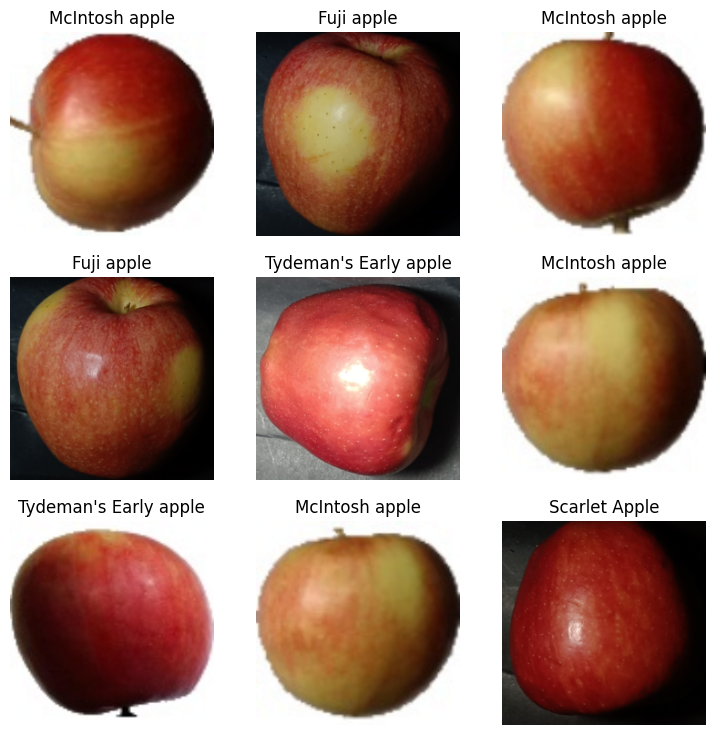

In [17]:
dls.show_batch()

In [18]:
model=vision_learner(
    dls=dls,
    arch=models.resnet50, 
    metrics=[accuracy, error_rate]
)


In [19]:
model.fine_tune(
     epochs=5
)

epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.254500,0.347685,0.836364,0.163636,01:36


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.178854,0.178479,0.945455,0.054545,01:51
1,0.113645,0.086997,0.981818,0.018182,01:57
2,0.094260,0.143368,0.963636,0.036364,01:56
3,0.066642,0.098264,0.963636,0.036364,01:56
4,0.055288,0.083581,0.963636,0.036364,01:54


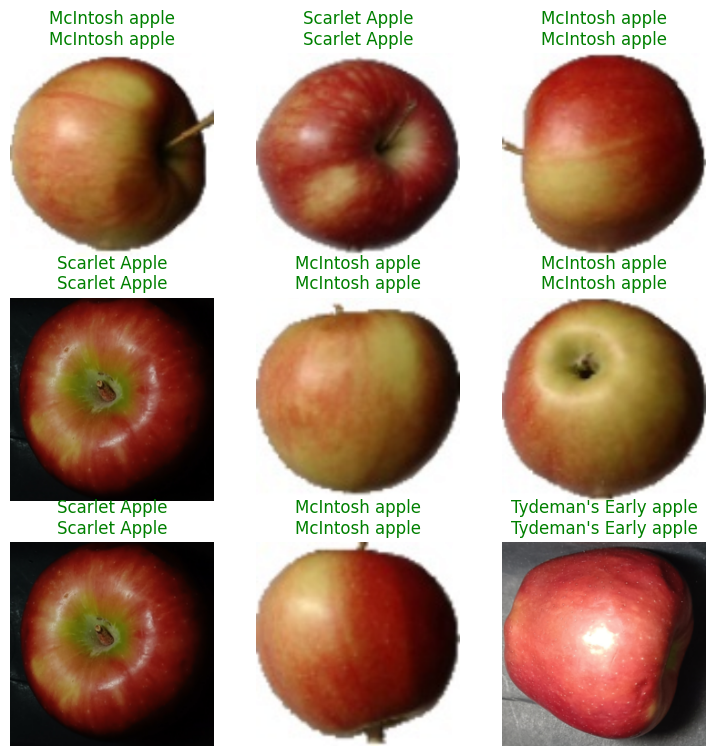

In [20]:
model.show_results()

In [21]:
#save model and predict

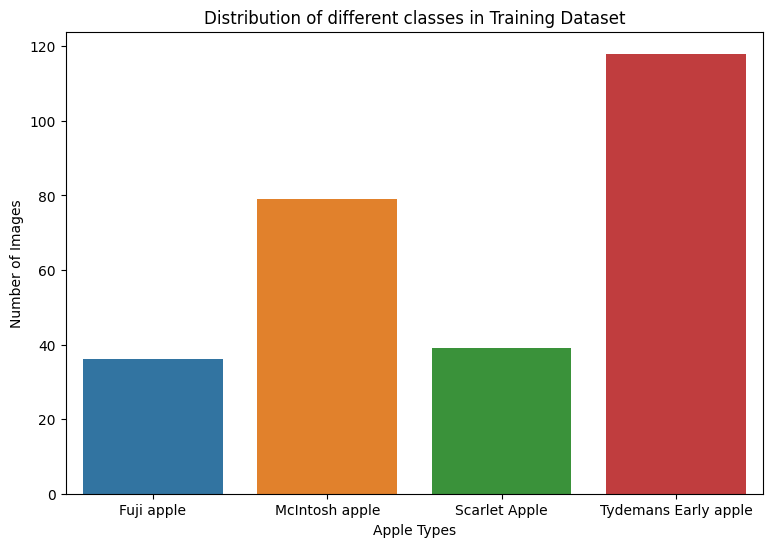

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

image_folder = ['Fuji apple', 'McIntosh apple', 'Scarlet Apple', 'Tydemans Early apple']
nimgs = {}

for i in image_folder:
    nimages = len(os.listdir("C:\\Users\\Administrator\\Desktop\\Fast.AI Data\\test\\" + i))
    nimgs[i] = nimages

plt.figure(figsize=(9, 6))
sns.barplot(x=list(nimgs.keys()), y=list(nimgs.values()))
plt.title('Distribution of different classes in Training Dataset')
plt.xlabel('Apple Types')
plt.ylabel('Number of Images')
plt.show()

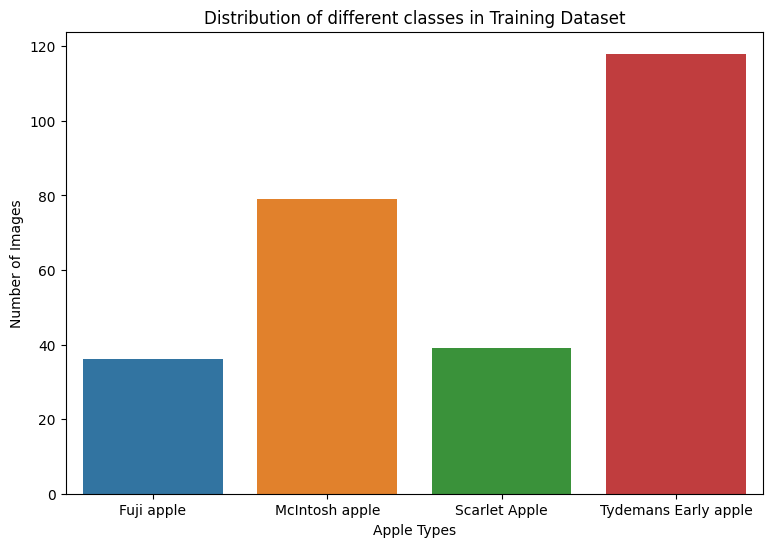

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

image_folder = ['Fuji apple', 'McIntosh apple', 'Scarlet Apple', 'Tydemans Early apple']
nimgs = {}

for folder in image_folder:
    path = "C:\\Users\\Administrator\\Desktop\\Fast.AI Data//test\\" + folder
    nimages = len(os.listdir(path))
    nimgs[folder] = nimages

plt.figure(figsize=(9, 6))
sns.barplot(x=list(nimgs.keys()), y=list(nimgs.values()))
plt.title('Distribution of different classes in Training Dataset')
plt.xlabel('Apple Types')
plt.ylabel('Number of Images')
plt.show()


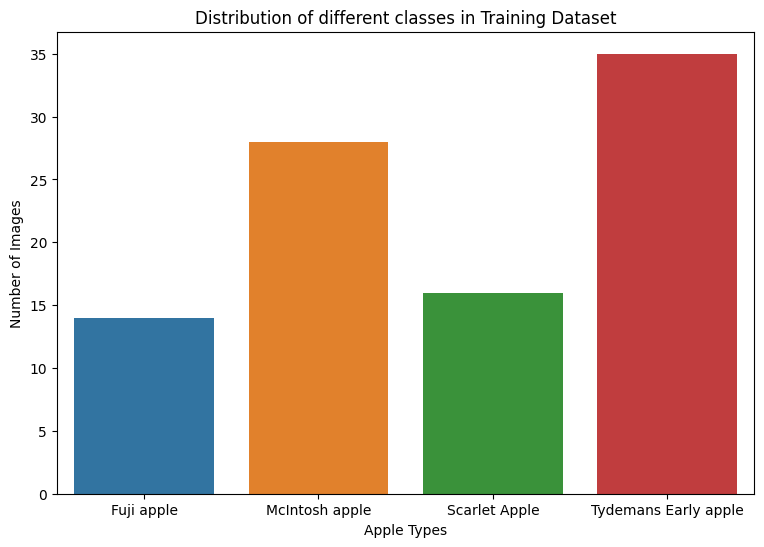

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

image_folder = ['Fuji apple', 'McIntosh apple', 'Scarlet Apple', 'Tydemans Early apple']
nimgs = {}

for folder in image_folder:
    path = "C:\\Users\\Administrator\\Desktop\\Fast.AI Data//validation\\" + folder
    nimages = len(os.listdir(path))
    nimgs[folder] = nimages

plt.figure(figsize=(9, 6))
sns.barplot(x=list(nimgs.keys()), y=list(nimgs.values()))
plt.title('Distribution of different classes in Training Dataset')
plt.xlabel('Apple Types')
plt.ylabel('Number of Images')
plt.show()

In [25]:
model.export('fruit_classifier1.pk1')

In [26]:
# Save the model
model.export(f'{DATASET_PATH}/fruit_classifier1.pkl')

# Load the learner
new_model = load_learner(f'{DATASET_PATH}/fruit_classifier1.pkl')




In [27]:
new_model.predict(
          item= "C:\\Users\\Administrator\\Desktop\\Quality Grading apple2\\Tydeman's Early apple\\17_100.jpg"
)

c:\Program Files\Python310\lib\site-packages\fastai\torch_core.py:263: UserWarning: 'has_mps' is deprecated, please use 'torch.backends.mps.is_built()'
  return getattr(torch, 'has_mps', False)


("Tydeman's Early apple",
 tensor(3),
 tensor([3.8227e-07, 3.3642e-10, 5.7478e-08, 1.0000e+00]))

Prediction: Fuji apple (Fuji apple)
Index: 0
Probabilities: tensor([9.9740e-01, 2.8289e-04, 1.7717e-03, 5.4131e-04])


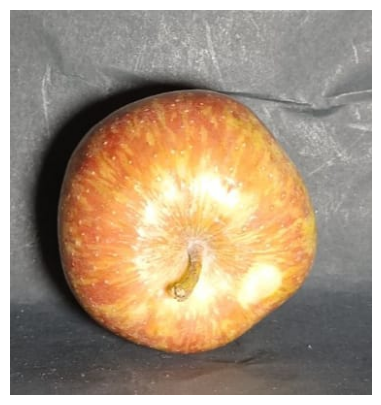

In [28]:
from fastai.vision.all import *

image_path = "C:\\Users\\Administrator\\Pictures\\apple2.jpg"
img = PILImage.create(image_path)
show_image(img)

# Assuming `new_model` is already loaded
prediction, idx, probabilities = new_model.predict(img)
class_names = new_model.dls.vocab
predicted_class = class_names[idx]

print(f"Prediction: {predicted_class} ({prediction})")
print(f"Index: {idx}")
print(f"Probabilities: {probabilities}")


In [29]:
#test
print(model.recorder.values)

[[0.0003202929219696671, 1.0, 0.0]]


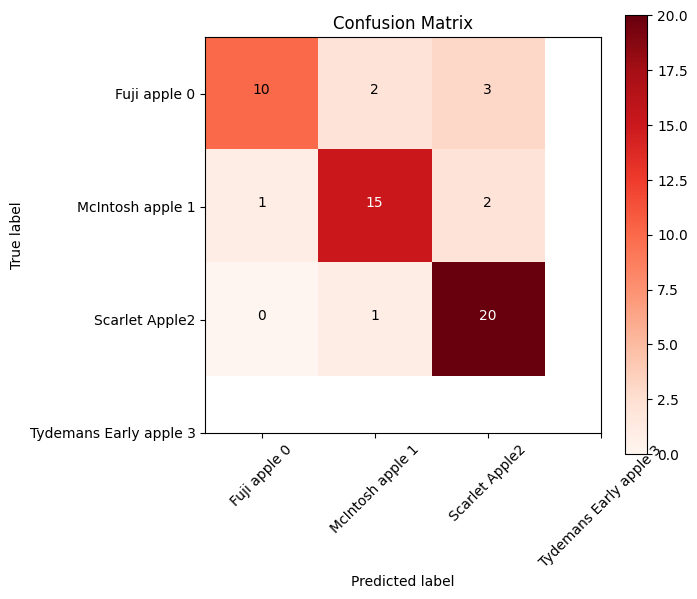

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import itertools
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Assuming conf_mat is your confusion matrix and classes is the list of class names
# Replace this with your actual confusion matrix and class names

# Example confusion matrix
conf_mat = np.array([[10, 2, 3],
                    [1, 15, 2],
                    [0, 1, 20]])

# Example class names
classes = ['Fuji apple 0', 'McIntosh apple 1', 'Scarlet Apple2','Tydemans Early apple 3']

def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Reds):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        cm = cm.round(2)

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

# Plot confusion matrix
np.set_printoptions(precision=2)
fig1 = plt.figure(figsize=(7, 6))
plot_confusion_matrix(conf_mat, classes=classes, title='Confusion Matrix')
plt.show()


c:\Program Files\Python310\lib\site-packages\fastai\torch_core.py:263: UserWarning: 'has_mps' is deprecated, please use 'torch.backends.mps.is_built()'
  return getattr(torch, 'has_mps', False)


epoch,train_loss,valid_loss,accuracy,time
0,1.467092,0.300694,0.875000,01:24


epoch,train_loss,valid_loss,accuracy,time
0,0.252250,0.023138,1.000000,01:51
1,0.160015,0.002284,1.000000,01:52
2,0.119047,0.006890,1.000000,01:53
3,0.108926,0.001524,1.000000,01:52
4,0.088543,0.001719,1.000000,01:58


c:\Program Files\Python310\lib\site-packages\fastai\torch_core.py:263: UserWarning: 'has_mps' is deprecated, please use 'torch.backends.mps.is_built()'
  return getattr(torch, 'has_mps', False)


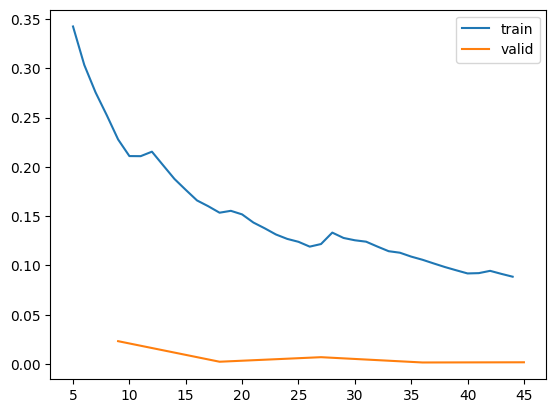

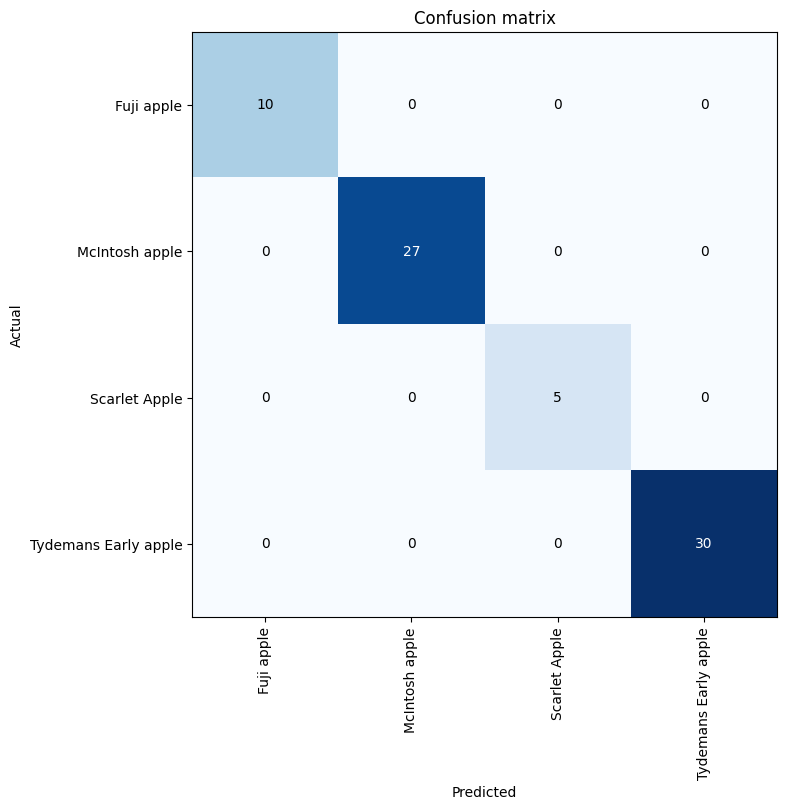

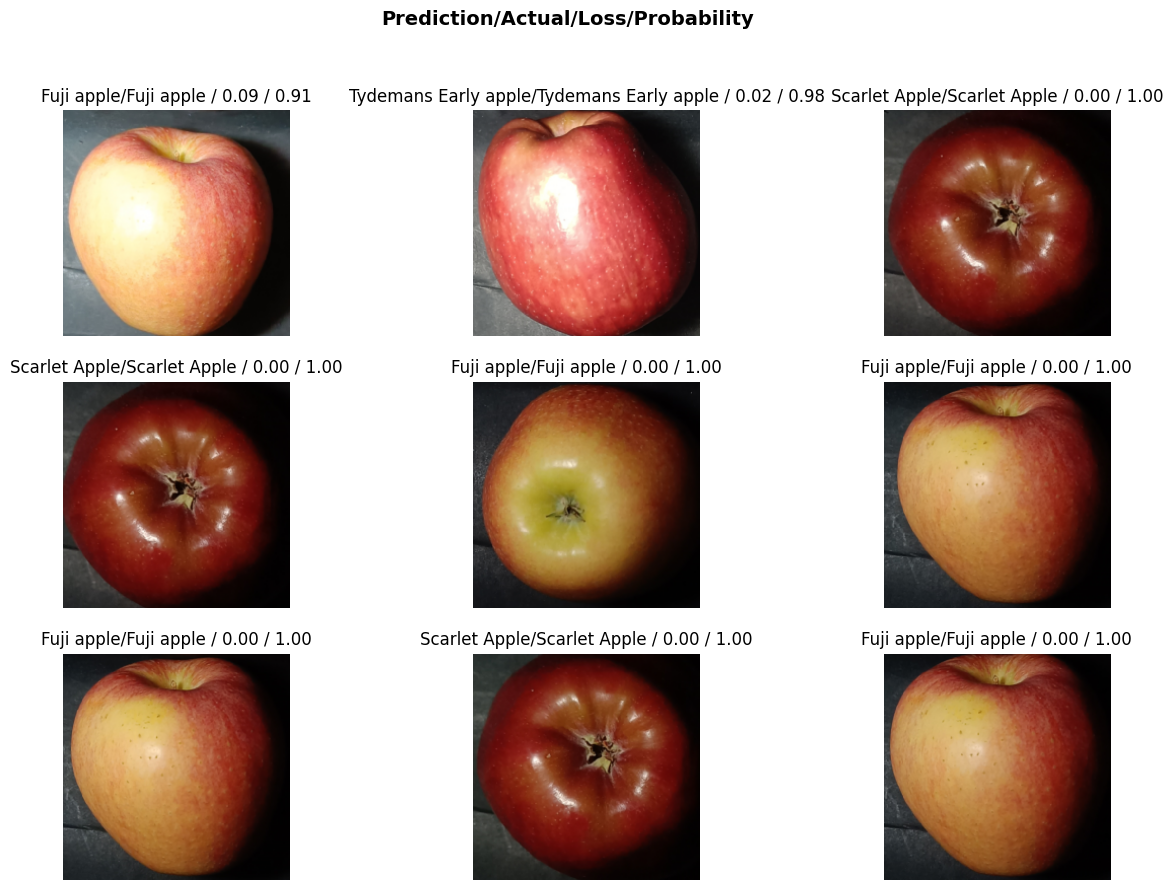

In [31]:

import warnings
from fastai.vision.all import *

# Suppress the deprecated 'has_mps' warning
warnings.filterwarnings("ignore", category=UserWarning, module="torch.backends.mps")

# Define your data block
data = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=Resize(460),
    batch_tfms=[*aug_transforms(size=224), Normalize.from_stats(*imagenet_stats)]
)

# Create a dataloaders object
dls = data.dataloaders("C:\\Users\\Administrator\\Desktop\\Multi-class Image Classification\\apple-data", bs=32)

# Create a CNN Learner
learn = vision_learner(dls, resnet34, metrics=[accuracy])

# Fine-tune the model
learn.fine_tune(5)

# Plot training and validation loss
learn.recorder.plot_loss()

# Display confusion matrix
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix(figsize=(8, 8))

# Display top losses
interp.plot_top_losses(9, figsize=(15, 10))

# Show results
plt.show()
